# Apply a Support Vector Machine (SVM) to classify URLs into legitimate and malicious categories 

In [1]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Load dataset
df = pd.read_csv("phishing_url_dataset.csv")

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (200000, 2)
                                                 URL  Label
0  http://electrocoatingmovilparticulares.mobi/w3...      0
1                       https://www.clonefluence.com      1
2  http://wonoplata.org.ru/olb/5kmxq5zu/mrandapay...      0
3                              https://www.snohd.org      1
4                     https://www.revelrypartyco.com      1


In [2]:
def extract_features(url):
    return pd.Series({
        "url_length": len(url),
        "num_dots": url.count("."),
        "num_digits": sum(c.isdigit() for c in url),
        "num_special": len(re.findall(r"[^a-zA-Z0-9]", url)),
        "has_https": int(url.startswith("https://")),
        "has_ip": int(bool(re.search(r"\d{1,3}(\.\d{1,3}){3}", url)))
    })


# Extract features
features = df["URL"].apply(extract_features)

# Add target
features["Label"] = df["Label"]

print(features.head())

   url_length  num_dots  num_digits  num_special  has_https  has_ip  Label
0          76         2           7            8          0       0      0
1          28         2           0            5          1       0      1
2          81         2          10           14          0       0      0
3          21         2           0            5          1       0      1
4          30         2           0            5          1       0      1


In [3]:
X = features.drop("Label", axis=1)
y = features["Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 160000
Testing samples: 40000


In [4]:
from sklearn.svm import LinearSVC

model = LinearSVC(
    random_state=42,
    max_iter=5000
)

model.fit(X_train, y_train)

print("SVM model trained successfully.")

SVM model trained successfully.


In [5]:
y_pred = model.predict(X_test)

print("Predictions completed.")
print("First 10 predictions:")
print(y_pred[:10])

Predictions completed.
First 10 predictions:
[1 0 0 0 1 1 0 0 1 1]


In [6]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Legitimate", "Malicious"]
    )
)

Accuracy: 0.938

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.98      0.89      0.94     20000
   Malicious       0.90      0.98      0.94     20000

    accuracy                           0.94     40000
   macro avg       0.94      0.94      0.94     40000
weighted avg       0.94      0.94      0.94     40000



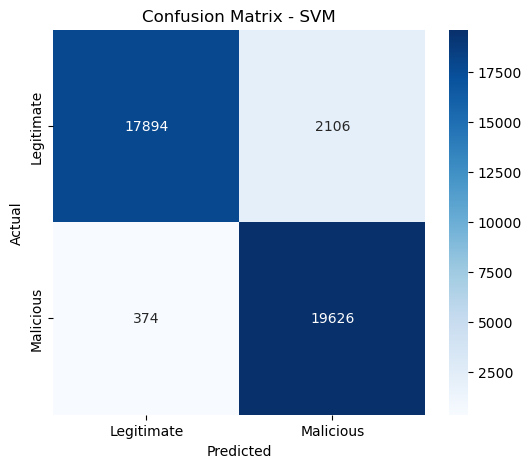

In [7]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Malicious"],
    yticklabels=["Legitimate", "Malicious"]
)

plt.title("Confusion Matrix - SVM")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

c:\Users\bhuva\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearSVC was fitted with feature names
  warnings.warn(


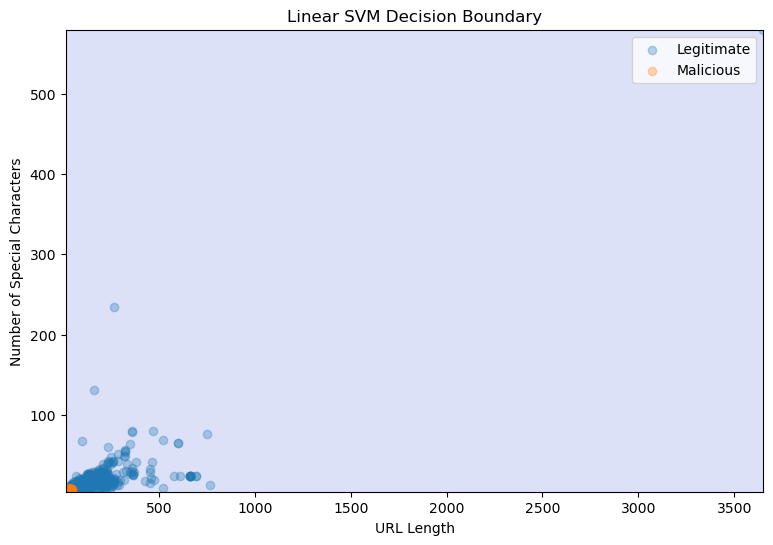

In [9]:
import numpy as np

# Select two features for visualization
sample = features.sample(
    n=5000,
    random_state=42
)

X_vis = sample[["url_length", "num_special"]]
y_vis = sample["Label"]

# Train Linear SVM using two features
svm_visual = LinearSVC(
    random_state=42,
    max_iter=5000
)

svm_visual.fit(X_vis, y_vis)

# Create grid
x_min = X_vis["url_length"].min()
x_max = X_vis["url_length"].max()

y_min = X_vis["num_special"].min()
y_max = X_vis["num_special"].max()

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

# Predict grid points
Z = svm_visual.predict(
    np.c_[xx.ravel(), yy.ravel()]
)

Z = Z.reshape(xx.shape)

# Plot decision regions
plt.figure(figsize=(9, 6))

plt.contourf(
    xx,
    yy,
    Z,
    alpha=0.2,
    cmap="coolwarm"
)

# Plot legitimate URLs
plt.scatter(
    X_vis[y_vis == 0]["url_length"],
    X_vis[y_vis == 0]["num_special"],
    label="Legitimate",
    alpha=0.3
)

# Plot malicious URLs
plt.scatter(
    X_vis[y_vis == 1]["url_length"],
    X_vis[y_vis == 1]["num_special"],
    label="Malicious",
    alpha=0.3
)

plt.xlabel("URL Length")
plt.ylabel("Number of Special Characters")
plt.title("Linear SVM Decision Boundary")
plt.legend()

plt.show()